<a href="https://colab.research.google.com/github/amolloelly-png/AI-for-Science-and-Engineering/blob/main/Week_5_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Building Your First Supervised Machine Learning Model
**Objective:** predict a petroleum station's `historical_risk_classification` using station characteristics and recorded safety/compliance indicators.

This is a **classification** task because the target is categorical (`Low`, `Medium`, `High`, `Critical`), not a continuous numerical value.


## 1. Importing libraries and loading the dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

DATA_PATH = "/content/kenya_petroleum_stations_safety_dataset-3.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (200, 34)


,station_id,station_name,location,county_region,facility_type,year_established,num_dispensers,num_staff,pms_storage_capacity_litres,ago_storage_capacity_litres,...,oil_water_separator_status,spill_kit_status,calibration_status,days_since_last_calibration,last_inspection_date,previous_inspection_findings,non_compliance_severity,previous_incident,incident_year,historical_risk_classification
0,KE-PS-0001,Station 1,"Town Centre, Kiambu",Kiambu,Service Station,2021,2,9,20000,30000,...,Present & Functional,Expired Materials,Due Within 30 Days,321.0,2025-06-28,Lightning arrestor disconnected,Medium,Minor fuel spill (contained),2025.0,Medium
1,KE-PS-0002,Station 2,"Highway, Marsabit",Marsabit,Retail Filling Station,2015,4,21,80000,30000,...,Present & Functional,Available,Overdue,123.0,2025-06-23,Pump calibration overdue,NaN,Electrical short circuit,2021.0,Medium
2,KE-PS-0003,Station 3,"Highway, Trans Nzoia",Trans Nzoia,Retail Filling Station,2012,4,21,40000,30000,...,Present & Functional,Incomplete,Overdue,141.0,2025-05-29,Underground tank integrity concerns; Fire exti...,NaN,None recorded,NaN,Medium
3,KE-PS-0004,Station 4,"Town Centre, Kericho",Kericho,Urban Mini Station,2007,9,7,60000,20000,...,Present & Functional,NaN,Due Within 30 Days,226.0,2026-08-12,No major findings,Medium,None recorded,NaN,High
4,KE-PS-0005,Station 5,"Industrial Area, Mombasa",Mombasa,Service Station,2010,2,20,30000,30000,...,Present & Functional,Available,Up to Date,40.0,2026-06-30,Staff PPE non-compliance,Low,None recorded,NaN,Low


## 2. Inspect the data and target

The **target/output** is `historical_risk_classification`.

The features are the station's physical characteristics and recorded compliance/safety fields. Station IDs/names, the inspection date, and incident history fields (`previous_incident`, `incident_year`) have been excluded to reduce identifier effects and avoid using direct incident-history information as a shortcut. Also exclude is `non_compliance_severity` because it may overlap strongly with the risk label and has many missing values.



In [ ]:
TARGET = "historical_risk_classification"

print("Target counts:")
display(df[TARGET].value_counts().rename_axis("risk_class").to_frame("count"))

print("Missing values in columns:")
display(df.isna().sum().sort_values(ascending=False).head(12).to_frame("missing_count"))

df[TARGET] = df[TARGET].astype(str).str.strip()


Target counts:


,count
risk_class,
Medium,92
High,63
Low,27
Critical,18


Missing values in columns:


,missing_count
incident_year,133
lpg_compliance_status,59
non_compliance_severity,51
spill_kit_status,26
days_since_last_calibration,10
station_id,0
station_name,0
location,0
facility_type,0
county_region,0


## 3. Define features and split into training and test sets

We use an **80/20 train-test split**.

In [ ]:
excluded_columns = [
    TARGET,
    "station_id",
    "station_name",
    "last_inspection_date",
    "previous_incident",
    "incident_year",
    "non_compliance_severity",
]

X = df.drop(columns=[c for c in excluded_columns if c in df.columns])
y = df[TARGET]

# Treat boolean columns as categorical for clear, consistent preprocessing.
for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Training rows: 160
Test rows: 40

Training target proportions:


,proportion
historical_risk_classification,
Critical,0.0875
High,0.3125
Low,0.1375
Medium,0.4625



Test target proportions:


,proportion
historical_risk_classification,
Critical,0.100
High,0.325
Low,0.125
Medium,0.450


Numeric features: ['year_established', 'num_dispensers', 'num_staff', 'pms_storage_capacity_litres', 'ago_storage_capacity_litres', 'lpg_storage_capacity_kg', 'lpg_cylinder_count', 'num_fire_extinguishers', 'num_sand_buckets', 'num_fire_points', 'days_since_last_calibration']
Categorical features: ['location', 'county_region', 'facility_type', 'has_lpg', 'lpg_compliance_status', 'fire_extinguisher_condition', 'emergency_shutdown_status', 'leakage_observation', 'earthing_compliance', 'electrical_safety_status', 'lightning_protection', 'environmental_compliance', 'oil_water_separator_status', 'spill_kit_status', 'calibration_status', 'previous_inspection_findings']


## 4. Selecting two supervised models

Both models use the same preprocessing:
- Numeric features: missing values are replaced with the training-set median.
- Categorical features: missing values are replaced with the most frequent category, then one-hot encoded.
- `handle_unknown="ignore"` lets the model handle categories that appear in the test data but not in training.

**Model 1: Decision Tree** — learns a sequence of feature-based rules.

**Model 2: Random Forest** — combines many decision trees trained on varied samples/features.

In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced",
            max_depth=5
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            min_samples_leaf=2
        ))
    ])
}


## 5. Train both models and predict on the test set

The test set is held out until evaluation. The `class_weight="balanced"` setting makes the algorithms pay more attention to less frequent classes during training.

In [ ]:
predictions = {}
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    predictions[name] = pipeline.predict(X_test)
    print(f"{name}: training complete")

comparison_rows = []
for name, y_pred in predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("Macro F1", ascending=False)
display(comparison.round(3))


Decision Tree: training complete
Random Forest: training complete


,Accuracy,Balanced accuracy,Macro F1,Weighted F1
Model,,,,
Random Forest,0.525,0.362,0.360,0.458
Decision Tree,0.425,0.274,0.268,0.413


## 6. Evaluate performance

- **Accuracy:** proportion of all test predictions that are correct.
- **Balanced accuracy:** average recall across classes, giving each class equal weight.
- **Macro F1:** F1 score calculated for each class and then averaged equally.
- **Weighted F1:** F1 averaged with each class weighted by its support.
- **Classification report:** precision, recall, and F1 for each class.
- **Confusion matrix:** shows which risk classes are most often confused.


Decision Tree
              precision    recall  f1-score   support

    Critical       0.00      0.00      0.00         4
        High       0.58      0.54      0.56        13
         Low       0.00      0.00      0.00         5
      Medium       0.48      0.56      0.51        18

    accuracy                           0.42        40
   macro avg       0.26      0.27      0.27        40
weighted avg       0.40      0.42      0.41        40



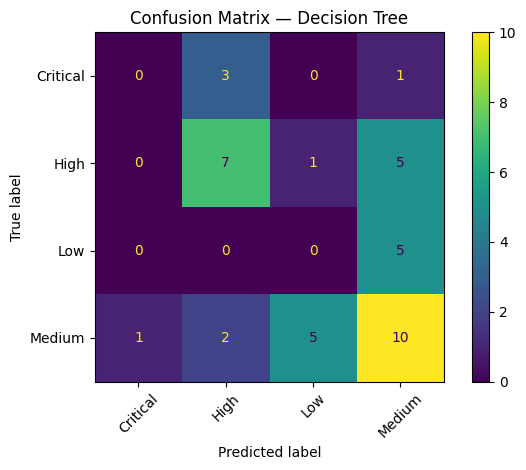

Random Forest
              precision    recall  f1-score   support

    Critical       1.00      0.25      0.40         4
        High       0.57      0.31      0.40        13
         Low       0.00      0.00      0.00         5
      Medium       0.50      0.89      0.64        18

    accuracy                           0.53        40
   macro avg       0.52      0.36      0.36        40
weighted avg       0.51      0.53      0.46        40



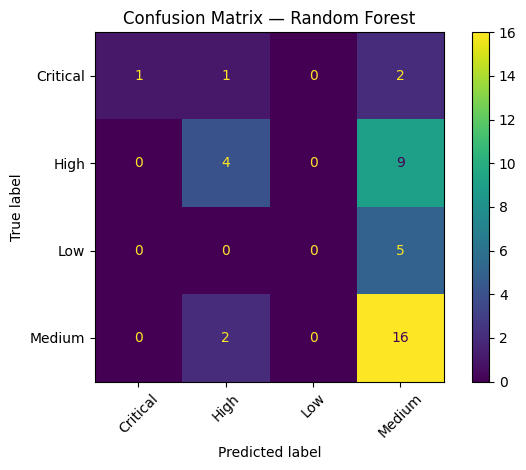

In [ ]:
for name, y_pred in predictions.items():
    print("=" * 72)
    print(name)
    print(classification_report(y_test, y_pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["Critical", "High", "Low", "Medium"],
        xticks_rotation=45,
        values_format="d"
    )
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()


## 7. Compare the models and discuss the results

### Result summary

**Random Forest is clearly stronger**: It achieves higher accuracy (53% vs 42%) and better overall F1 scores. It is the only model that correctly identifies any Critical samples (recall 0.25, precision 1.00) and shows solid performance on the majority Medium class (recall 0.89, F1 0.64).

**Both models fail completely on the Low class** (precision/recall/F1 = 0). This is almost certainly due to class imbalance — Low has only 5 samples in the test set, and Critical has only 4. The models are heavily biased toward the more frequent Medium (18) and High (13) classes.

**Decision Tree is weaker and more unstable**: It never predicts Critical or Low correctly, and its macro-averaged metrics are much lower. While it edges out Random Forest slightly on the High class, this is not enough to compensate for the overall poorer performance.

**Practical takeaway**: Random Forest is the better choice of the two. However, both results indicate the need for improvements such as class balancing (e.g., SMOTE or class weights), more data, feature engineering, or trying other models. The current performance is only modestly better than random guessing on a 4-class problem.